# X5: forecasting weekly store turnover

This notebook continues our team's **EDA_x5.ipynb**. We compare two simple
forecasts, Ridge regression and one boosted-tree model. We then choose a method,
check it on a separate historical period and forecast every requested store–week.

**Run from the x5_team4 folder.** Read the cells from top to bottom. Required
packages are listed in `requirements_modeling_v2.txt`. Source data stay unchanged;
generated files go to `results/modeling_v2/`. See `README.md` for data placement
and instructions for running the notebook.

In [1]:
# Libraries and display settings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
import json
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
pd.options.display.float_format = '{:.6f}'.format
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
DATA = Path('../MSC Case data 2026')
OUTPUT = Path('results/modeling_v2')
FIGURES = OUTPUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

## 1. Data preparation: continue the EDA

One row is one store in one week. `week` is a Monday date; `target` is turnover in
**conventional units**, not rubles or a percentage. Store IDs are labels.

The loading, date conversion and calendar fields below follow the team's EDA.
The paths are adapted for this folder. The extra checks are our modelling checks.
We reuse EDA findings on missing values, categories, store age and area. We do
not repeat all its charts or treat its correlations as proof of predictive value.

In [2]:
# From EDA: load the two files and prepare dates
train = pd.read_parquet(DATA / 'train.parquet')
test = pd.read_parquet(DATA / 'test_template.parquet')
print('Train shape:', train.shape)
print('Test shape:', test.shape)

for df in [train, test]:
    df['week'] = pd.to_datetime(df['week'])
    df['year'] = df['week'].dt.year
    df['month'] = df['week'].dt.month
    df['woy'] = df['week'].dt.isocalendar().week.astype(int)
    df['quarter'] = df['week'].dt.quarter

train = train.sort_values(['store_pseudo_id', 'week']).reset_index(drop=True)
KEY = ['store_pseudo_id', 'week']
REQUEST_COLUMNS = KEY + ['feature3', 'feature6', 'feature14']

Train shape: (321531, 25)
Test shape: (31586, 24)


In [3]:
# Added for modelling: briefly check the data before using it
print('Train dates:', train['week'].min(), 'to', train['week'].max())
print('Stores:', train['store_pseudo_id'].nunique())
print('Weeks:', train['week'].nunique())
print('Missing target:', train['target'].isna().sum())
print('Duplicate store-weeks in train:', train.duplicated(KEY).sum())
print('Duplicate store-weeks in test:', test.duplicated(KEY).sum())
print('Target range:', train['target'].min(), 'to', train['target'].max())

new_ids = set(test['store_pseudo_id']) - set(train['store_pseudo_id'])
print('New stores in test:', len(new_ids))
print('Their requested rows:', test['store_pseudo_id'].isin(new_ids).sum())

Train dates: 2023-07-10 00:00:00 to 2026-05-04 00:00:00
Stores: 3561
Weeks: 148
Missing target: 0
Duplicate store-weeks in train: 0
Duplicate store-weeks in test: 0
Target range: 0.0 to 1.0
New stores in test: 168
Their requested rows: 702


## 2. Historical evaluation

| Last available week | Predict the next nine weeks | Purpose |
|---|---|---|
| 3 March 2025 | 10 March–5 May 2025 | Select the model |
| 5 May 2025 | 12 May–7 July 2025 | Select the model |
| 2 March 2026 | 9 March–4 May 2026 | Control after selection |

Each method predicts the **same observed future keys**. New stores and partial
histories stay in the comparison. We assume the future store list and its region,
area and planned opening information are known, as in the supplied template.
We do not predict openings or closures.

The March–May 2026 period was explored earlier, so the control is **not a blind
test**. It is excluded from the selection score. No control outcomes enter fitting
or change the choice. We use the original target scale: the Q&A allows values above
one, so the EDA's exploratory logit transformation is not used for forecasting.

In [4]:
# Dates and model inputs, shared by all methods
selection_dates = [pd.Timestamp('2025-03-03'), pd.Timestamp('2025-05-05')]
control_date = pd.Timestamp('2026-03-02')
final_date = pd.Timestamp('2026-05-04')

numeric = ['last_value', 'mean_4w', 'n_recent', 'has_history',
           'gap_weeks', 'horizon', 'log_age', 'log_area']
categorical = ['region', 'forecast_month']
FEATURES = numeric + categorical

### Build the information available at an origin

We use one function because the same preparation is repeated for many origins.
It takes past data and a request table and returns one row per requested pair.
The four-week mean uses **calendar weeks**, not four arbitrary previous rows.

**Established** means all latest 26 weeks are observed. **Limited history** means
some history exists but not all 26 weeks. **New / no history** means none exists.
A missing week does not mean zero turnover or prove that a store closed.

In [5]:
def make_inputs(data, requests, origin):
    # Keep only information available at this origin
    past = data[data['week'] <= origin]
    last = past.drop_duplicates('store_pseudo_id', keep='last')
    last = last.set_index('store_pseudo_id')
    recent = past[past['week'] >= origin - pd.Timedelta(weeks=3)]
    recent26 = past[past['week'] >= origin - pd.Timedelta(weeks=25)]

    x = requests.reset_index(drop=True).copy()
    store = x['store_pseudo_id']
    x['last_value'] = store.map(last['target'])
    x['last_date'] = store.map(last['week'])
    x['has_history'] = x['last_value'].notna().astype(int)
    x['n_recent'] = store.map(recent.groupby('store_pseudo_id').size()).fillna(0)
    x['mean_4w'] = store.map(recent.groupby('store_pseudo_id')['target'].mean())
    x['mean_4w'] = x['mean_4w'].fillna(x['last_value']).fillna(0)
    x['gap_weeks'] = (origin - x['last_date']).dt.days / 7
    x['gap_weeks'] = x['gap_weeks'].fillna(0)

    # Assign history groups from the past, not from future turnover
    count26 = store.map(recent26.groupby('store_pseudo_id').size())
    x['history_group'] = 'Limited history'
    x.loc[count26 == 26, 'history_group'] = 'Established'
    x.loc[x['has_history'] == 0, 'history_group'] = 'New / no history'

    # Zero is a placeholder only when has_history is zero
    x['last_value'] = x['last_value'].fillna(0)
    x['region'] = store.map(last['feature3']).fillna(x['feature3']).fillna('Unknown')
    x['region'] = x['region'].astype(str)
    area = store.map(last['feature6']).fillna(x['feature6'])
    x['log_area'] = np.log1p(area)
    x['log_age'] = np.log1p(x['feature14'])
    x['forecast_month'] = x['week'].dt.month.astype(str)
    x['horizon'] = ((x['week'] - origin).dt.days / 7).astype(int)
    return x

## 3. Two simple methods

**Latest:** repeat the last observed turnover. **Mean4:** average observations in
the latest four calendar weeks. With one to three observations, use their mean;
with no recent observations but older history, use the last value.

Both use the **same peer median** when no own history exists. Donors come from
the previous 52 weeks. First try region × age band; if fewer than five donor stores
are present, try the age band nationally, then all donors. Age bands are 0–27,
28–90, 91–364 and 365+ days. These are starting heuristics, not optimised thresholds.
Only the fallback for new stores can change with future age within the horizon.

In [6]:
def baseline_forecasts(data, x, origin):
    # Own-history forecasts
    forecasts = x[KEY + ['horizon', 'history_group']].copy()
    forecasts['Latest'] = x['last_value']
    forecasts['Mean4'] = x['mean_4w']
    forecasts['route'] = 'own_history'

    # Peer medians are calculated from the past only
    donors = data[data['week'].between(origin - pd.Timedelta(weeks=51), origin)].copy()
    bins = [-1, 27, 90, 364, np.inf]
    donors['age_band'] = pd.cut(donors['feature14'], bins, labels=False)
    donors['region'] = donors['feature3'].fillna('Unknown').astype(str)
    regional = donors.groupby(['region', 'age_band']).agg(
        median=('target', 'median'), stores=('store_pseudo_id', 'nunique'))
    national = donors.groupby('age_band').agg(
        median=('target', 'median'), stores=('store_pseudo_id', 'nunique'))
    overall = donors['target'].median()

    # Only stores without history need the reserve rule
    new_stores = x[x['has_history'] == 0].copy()
    new_stores['age_band'] = pd.cut(new_stores['feature14'], bins, labels=False)
    for i, row in new_stores.iterrows():
        group = (row['region'], row['age_band'])
        age = row['age_band']
        if group in regional.index and regional.loc[group, 'stores'] >= 5:
            value = regional.loc[group, 'median']
            route = 'peer_region_age'
        elif age in national.index and national.loc[age, 'stores'] >= 5:
            value = national.loc[age, 'median']
            route = 'peer_age'
        else:
            value = overall
            route = 'peer_global'
        forecasts.loc[i, ['Latest', 'Mean4']] = value
        forecasts.loc[i, 'route'] = route
    return forecasts

### Measure the errors

**MAE** is the average absolute error. **RMSE** gives large misses more influence.
**Bias** averages prediction minus actual: positive means overprediction. All three
use the same conventional units as turnover.

The next two short functions let us score every method in the same way. Actual
outcomes are joined only after predictions have been made.

In [7]:
def evaluate(forecasts, actuals, origin, methods):
    table = forecasts.merge(actuals, on=KEY)
    results = []
    for method in methods:
        part = table[KEY + ['horizon', 'history_group', 'target', 'route']].copy()
        part = part.rename(columns={'target': 'actual', 'route': 'forecast_route'})
        part['method'] = method
        part['origin'] = origin
        part['raw_prediction'] = table[method]
        part['prediction'] = part['raw_prediction'].clip(lower=0)
        part['error'] = part['prediction'] - part['actual']
        part['absolute_error'] = part['error'].abs()
        part['squared_error'] = part['error'] ** 2
        results.append(part)
    return pd.concat(results, ignore_index=True)

def metrics(results, groups):
    summary = results.groupby(groups).agg(
        n_rows=('actual', 'size'), n_stores=('store_pseudo_id', 'nunique'),
        MAE=('absolute_error', 'mean'), MSE=('squared_error', 'mean'),
        Bias=('error', 'mean')).reset_index()
    summary['RMSE'] = np.sqrt(summary['MSE'])
    return summary.drop(columns='MSE')

## 4. First finish the baseline comparison

Use every observed future key in each selection window, including new stores.
The selection score gives the two periods equal weight. It is not the MAE of all
rows pooled together.

In [8]:
development_parts = []
selection_data = {}
for origin in selection_dates:
    weeks = pd.date_range(origin + pd.Timedelta(weeks=1), periods=9, freq='W-MON')
    future = train[train['week'].isin(weeks)]
    requests = future[REQUEST_COLUMNS]
    actuals = future[KEY + ['target']]
    x = make_inputs(train, requests, origin)
    forecasts = baseline_forecasts(train, x, origin)
    selection_data[origin] = (x, forecasts, actuals)
    development_parts.append(evaluate(forecasts, actuals, origin, ['Latest', 'Mean4']))

development = pd.concat(development_parts, ignore_index=True)
baseline_metrics = metrics(development, ['origin', 'method'])
print(baseline_metrics)
baseline_scores = baseline_metrics.groupby('method')['MAE'].mean()
best_baseline = baseline_scores.idxmin()
print()
print('Best preliminary baseline:', best_baseline)

      origin  method  n_rows  n_stores      MAE      Bias     RMSE
0 2025-03-03  Latest   22257      2533 0.017387 -0.008715 0.025692
1 2025-03-03   Mean4   22257      2533 0.016465 -0.006749 0.025098
2 2025-05-05  Latest   23438      2685 0.017860  0.001748 0.025931
3 2025-05-05   Mean4   23438      2685 0.020373 -0.001693 0.030376

Best preliminary baseline: Latest


In [9]:
# Save a full preliminary forecast before working on regression
final_requests = test[REQUEST_COLUMNS]
x_final = make_inputs(train, final_requests, final_date)
baseline_final = baseline_forecasts(train, x_final, final_date)
preliminary = test[KEY].copy()
preliminary['target'] = baseline_final[best_baseline].to_numpy()
preliminary.to_csv(OUTPUT / 'baseline_forecast.csv', index=False, date_format='%Y-%m-%d')
print('Preliminary forecast rows:', len(preliminary))

Preliminary forecast rows: 31586


## 5. Prepare learning examples for regression

For each historical origin, predict one to nine weeks ahead. Inputs stop at that
origin; target dates must not exceed the external training cutoff. Include stores
with no past turnover so the regression learns these cases too.

Origins are sampled every four weeks to reduce computation. This is a practical
choice, not a claim that four weeks is optimal.

In [10]:
def training_examples(cutoff):
    available = train[train['week'] <= cutoff]
    origins = pd.date_range(train['week'].min(), cutoff - pd.Timedelta(weeks=1), freq='4W-MON')
    inputs, targets, dates = [], [], []
    for origin in origins:
        first = origin + pd.Timedelta(weeks=1)
        last = origin + pd.Timedelta(weeks=9)
        future = available[available['week'].between(first, last)]
        if len(future) == 0:
            continue
        x = make_inputs(available, future[REQUEST_COLUMNS], origin)
        inputs.append(x[FEATURES])
        targets.append(future['target'].to_numpy())
        dates.append(future['week'].to_numpy())
    X = pd.concat(inputs, ignore_index=True)
    X[numeric] = X[numeric].astype('float32')
    return X, np.concatenate(targets), pd.to_datetime(np.concatenate(dates))

## 6. Define two regression candidates

**Ridge** uses one pooled linear equation: turnover = intercept + weighted inputs.
It minimises squared errors plus a penalty on coefficient size, with fixed alpha=1.
Numeric inputs are scaled; region and month are encoded as categories.

`Pipeline` keeps these preparation steps and the estimator together, so each fit
learns them only from that training sample. `ColumnTransformer` simply applies
different preparation to numeric and categorical columns.

In [11]:
# Ridge: one additive model shared by stores and horizons
ridge_preparation = ColumnTransformer([
    ('numeric', StandardScaler(), numeric),
    ('category', OneHotEncoder(handle_unknown='ignore'), categorical)
], sparse_threshold=1.0)
ridge = Pipeline([
    ('preparation', ridge_preparation),
    ('model', Ridge(alpha=1.0, solver='lsqr'))
])

**Boosted trees** test one additional hypothesis: the nonlinear associations in EDA
may help beyond an additive line. The model combines small trees that correct
previous errors. It uses the same inputs and training rows as Ridge.

Region and month are marked categorical, so their integer codes are labels rather
than numerical distances. Settings are fixed below; early stopping is disabled.
No control outcomes or parameter search are used. These settings are not optimised.

In [12]:
# Boosting: one nonlinear alternative, with fixed settings
tree_preparation = ColumnTransformer([
    ('numeric', 'passthrough', numeric),
    ('category', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan), categorical)
])
tree_model = HistGradientBoostingRegressor(
    learning_rate=0.06, max_iter=150, max_leaf_nodes=15,
    min_samples_leaf=40, l2_regularization=10,
    early_stopping=False, random_state=RANDOM_STATE,
    categorical_features=[len(numeric), len(numeric) + 1]
)
boosted = Pipeline([('preparation', tree_preparation), ('model', tree_model)])
models = {'Ridge': ridge, 'Boosted trees': boosted}

## 7. Compare the learned models on selection periods

Train each model from scratch at each cutoff. Their inputs contain no future
turnover. The thread limit keeps CPU use modest; it does not alter the modelling
recipe. A more complex method is allowed to lose.

In [13]:
for origin in selection_dates:
    X, y, target_dates = training_examples(origin)
    print(origin.date(), ':', len(X), 'learning rows;', (X['has_history'] == 0).sum(), 'without history')
    x, forecasts, actuals = selection_data[origin]
    for name, model in models.items():
        with threadpool_limits(limits=4):
            model.fit(X, y)
            prediction = model.predict(x[FEATURES])
        scored = forecasts.copy()
        scored[name] = prediction
        scored['route'] = 'direct_regression'
        development_parts.append(evaluate(scored, actuals, origin, [name]))

development = pd.concat(development_parts, ignore_index=True)
period_metrics = metrics(development, ['origin', 'method'])
print(period_metrics)

2025-03-03 : 316166 learning rows; 18726 without history


2025-05-05 : 365620 learning rows; 20118 without history


      origin         method  n_rows  n_stores      MAE      Bias     RMSE
0 2025-03-03  Boosted trees   22257      2533 0.017998  0.006142 0.026350
1 2025-03-03         Latest   22257      2533 0.017387 -0.008715 0.025692
2 2025-03-03          Mean4   22257      2533 0.016465 -0.006749 0.025098
3 2025-03-03          Ridge   22257      2533 0.018824  0.007241 0.025702
4 2025-05-05  Boosted trees   23438      2685 0.020319 -0.000113 0.029840
5 2025-05-05         Latest   23438      2685 0.017860  0.001748 0.025931
6 2025-05-05          Mean4   23438      2685 0.020373 -0.001693 0.030376
7 2025-05-05          Ridge   23438      2685 0.020117  0.001565 0.029280


In [14]:
# Show a few learning rows: each input belongs to its earlier origin
example_rows = [0, len(X) // 2, len(X) - 1]
learning_example = X.iloc[example_rows].copy()
learning_example['target_week'] = target_dates[example_rows]
learning_example['origin'] = learning_example['target_week'] - pd.to_timedelta(learning_example['horizon'] * 7, unit='D')
learning_example['target'] = y[example_rows]
print(learning_example[['origin', 'target_week', 'horizon', 'last_value', 'mean_4w', 'target']])

           origin target_week  horizon  last_value  mean_4w   target
0      2023-07-10  2023-07-17 1.000000    0.335401 0.335401 0.345810
182810 2024-08-05  2024-09-09 5.000000    0.185598 0.188737 0.202999
365619 2025-04-14  2025-05-05 3.000000    0.252437 0.247660 0.261582


## 8. Freeze the choice before control

Choose the lowest mean of the two period MAEs. An exact tie favours simplicity.
Also inspect each period and history group: the average must not hide weaknesses.
The selected name and score are saved before the control is evaluated.

In [15]:
selection_scores = period_metrics.groupby('method')['MAE'].mean()
selection_scores = selection_scores.reindex(['Latest', 'Mean4', 'Ridge', 'Boosted trees'])
selection_scores = selection_scores.sort_values(kind='stable')
print(selection_scores)
selected_method = selection_scores.index[0]
print()
print('Chosen method:', selected_method)
print(metrics(development, ['origin', 'history_group', 'method']))

frozen_selection = {
    'selected_method': selected_method, 'baseline_reference': best_baseline,
    'selection_origins': [str(d.date()) for d in selection_dates],
    'control_origin': str(control_date.date()),
    'score': float(selection_scores.iloc[0]), 'control_used_for_selection': False
}
(OUTPUT / 'frozen_selection.json').write_text(json.dumps(frozen_selection, indent=2))

method
Latest          0.017624
Mean4           0.018419
Boosted trees   0.019158
Ridge           0.019471
Name: MAE, dtype: float64

Chosen method: Latest
       origin     history_group         method  n_rows  n_stores      MAE      Bias     RMSE
0  2025-03-03       Established  Boosted trees   17266      1919 0.018032  0.008002 0.025905
1  2025-03-03       Established         Latest   17266      1919 0.016427 -0.007132 0.023888
2  2025-03-03       Established          Mean4   17266      1919 0.015469 -0.004928 0.023357
3  2025-03-03       Established          Ridge   17266      1919 0.018437  0.008551 0.024672
4  2025-03-03   Limited history  Boosted trees    4365       485 0.013777  0.002846 0.018858
5  2025-03-03   Limited history         Latest    4365       485 0.016980 -0.013168 0.024074
6  2025-03-03   Limited history          Mean4    4365       485 0.016068 -0.011861 0.022906
7  2025-03-03   Limited history          Ridge    4365       485 0.016481  0.004824 0.021227
8  2025

238

## 9. Separate retrospective control

Evaluate the frozen method and the two simple rules. Ridge is also shown for
diagnosis and the worked example, but it cannot become the winner after viewing
control errors. Refit using only data through 2 March 2026. Keep the decision fixed.

In [16]:
weeks = pd.date_range(control_date + pd.Timedelta(weeks=1), periods=9, freq='W-MON')
future = train[train['week'].isin(weeks)]
x_control = make_inputs(train, future[REQUEST_COLUMNS], control_date)
control_forecasts = baseline_forecasts(train, x_control, control_date)
control_names = ['Latest', 'Mean4', 'Ridge']
if selected_method == 'Boosted trees':
    control_names.append('Boosted trees')

X, y, _ = training_examples(control_date)
for name in control_names:
    if name in models:
        with threadpool_limits(limits=4):
            models[name].fit(X, y)
            control_forecasts[name] = models[name].predict(x_control[FEATURES])

control = evaluate(control_forecasts, future[KEY + ['target']], control_date, control_names)
print(metrics(control, ['method']))
print(metrics(control, ['history_group', 'method']))
all_results = pd.concat([development, control], ignore_index=True)
all_results['role'] = 'Selection'
all_results.loc[all_results['origin'] == control_date, 'role'] = 'Control'

   method  n_rows  n_stores      MAE      Bias     RMSE
0  Latest   30375      3450 0.016064 -0.004451 0.023941
1   Mean4   30375      3450 0.016426 -0.008428 0.024806
2   Ridge   30375      3450 0.017264  0.004525 0.024256
      history_group  method  n_rows  n_stores      MAE      Bias     RMSE
0       Established  Latest   25133      2801 0.015390 -0.002959 0.022310
1       Established   Mean4   25133      2801 0.015601 -0.007306 0.023126
2       Established   Ridge   25133      2801 0.016654  0.004800 0.022951
3   Limited history  Latest    4654       518 0.015798 -0.010001 0.023906
4   Limited history   Mean4    4654       518 0.017027 -0.012483 0.025429
5   Limited history   Ridge    4654       518 0.016949  0.006009 0.023318
6  New / no history  Latest     588       131 0.046959 -0.024321 0.061727
7  New / no history   Mean4     588       131 0.046959 -0.024321 0.061727
8  New / no history   Ridge     588       131 0.045814 -0.018996 0.059799


## 10. One store to understand the calculation

Reuse the smallest ID with complete 26-week history and nine future observations.
This availability rule gives store 1306351. It is an illustration, not the main
sample or a reason to change the selected network method.

In [17]:
dates = pd.date_range(end=control_date, periods=26, freq='W-MON')
dates = dates.union(pd.date_range(control_date + pd.Timedelta(weeks=1), periods=9, freq='W-MON'))
counts = train[train['week'].isin(dates)].groupby('store_pseudo_id').size()
example_id = counts[counts == 35].index.min()
example = control[control['store_pseudo_id'] == example_id]
example_table = example.pivot(index='week', columns='method', values='prediction')
example_table['Actual'] = example.groupby('week')['actual'].first()
example_table['Latest absolute error'] = (example_table['Latest'] - example_table['Actual']).abs()
example_table['Mean4 absolute error'] = (example_table['Mean4'] - example_table['Actual']).abs()
print('Store:', example_id)
print(example_table)
print()
print('MAE = sum of nine absolute errors / 9')
print(example_table[['Latest absolute error', 'Mean4 absolute error']].mean())

Store: 1306351
method       Latest    Mean4    Ridge   Actual  Latest absolute error  Mean4 absolute error
week                                                                                       
2026-03-09 0.194175 0.190620 0.201476 0.190784               0.003391              0.000163
2026-03-16 0.194175 0.190620 0.202646 0.188346               0.005829              0.002275
2026-03-23 0.194175 0.190620 0.203816 0.185627               0.008548              0.004994
2026-03-30 0.194175 0.190620 0.204987 0.179170               0.015005              0.011451
2026-04-06 0.194175 0.190620 0.201328 0.187622               0.006553              0.002998
2026-04-13 0.194175 0.190620 0.202498 0.185904               0.008271              0.004716
2026-04-20 0.194175 0.190620 0.203669 0.187571               0.006604              0.003049
2026-04-27 0.194175 0.190620 0.204839 0.188868               0.005307              0.001753
2026-05-04 0.194175 0.190620 0.201896 0.188864               0.00

## 11. Results and diagnostic charts

Use the same colours for each method. Selection and control remain separate.
These charts show observed error variation; they are not prediction intervals.

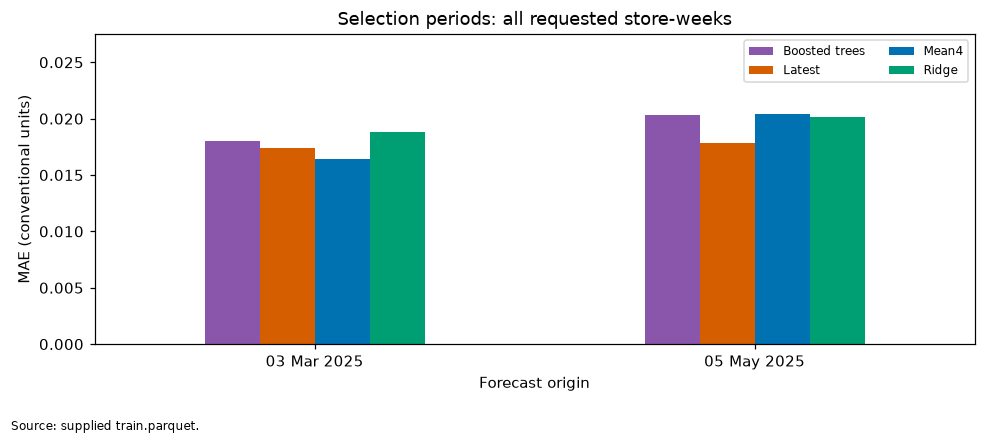

In [18]:
# Overall comparison on the two selection periods
colors = {'Latest': '#D55E00', 'Mean4': '#0072B2', 'Ridge': '#009E73', 'Boosted trees': '#8A56AC'}
comparison = period_metrics.pivot(index='origin', columns='method', values='MAE')
comparison.index = comparison.index.strftime('%d %b %Y')
comparison.plot.bar(figsize=(9, 4), color=[colors[m] for m in comparison.columns], rot=0)
plt.title('Selection periods: all requested store-weeks')
plt.ylabel('MAE (conventional units)')
plt.xlabel('Forecast origin')
plt.legend(fontsize=8, ncol=2)
plt.ylim(0, comparison.max().max() * 1.35)
plt.figtext(0.01, 0.01, 'Source: supplied train.parquet.', fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIGURES / 'model_comparison.png', dpi=160)
plt.show()

         role     history_group         method  n_rows  n_stores      MAE      Bias     RMSE
0     Control       Established         Latest   25133      2801 0.015390 -0.002959 0.022310
1     Control       Established          Mean4   25133      2801 0.015601 -0.007306 0.023126
2     Control       Established          Ridge   25133      2801 0.016654  0.004800 0.022951
3     Control   Limited history         Latest    4654       518 0.015798 -0.010001 0.023906
4     Control   Limited history          Mean4    4654       518 0.017027 -0.012483 0.025429
5     Control   Limited history          Ridge    4654       518 0.016949  0.006009 0.023318
6     Control  New / no history         Latest     588       131 0.046959 -0.024321 0.061727
7     Control  New / no history          Mean4     588       131 0.046959 -0.024321 0.061727
8     Control  New / no history          Ridge     588       131 0.045814 -0.018996 0.059799
9   Selection       Established  Boosted trees   35865      2071 0.019

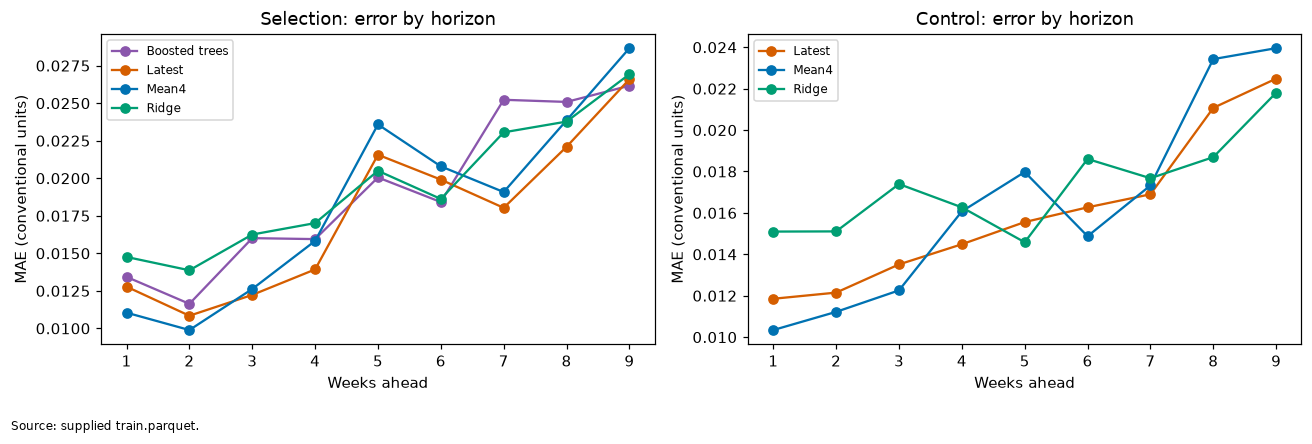

In [19]:
# Error by horizon and history group
group_metrics = metrics(all_results, ['role', 'history_group', 'method'])
print(group_metrics)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for role, ax in zip(['Selection', 'Control'], axes):
    subset = all_results[all_results['role'] == role]
    by_horizon = metrics(subset, ['horizon', 'method'])
    for name in by_horizon['method'].unique():
        line = by_horizon[by_horizon['method'] == name]
        ax.plot(line['horizon'], line['MAE'], 'o-', label=name, color=colors[name])
    ax.set_title(role + ': error by horizon')
    ax.set_xlabel('Weeks ahead')
    ax.set_ylabel('MAE (conventional units)')
    ax.legend(fontsize=8)
plt.figtext(0.01, 0.01, 'Source: supplied train.parquet.', fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIGURES / 'error_by_horizon.png', dpi=160)
plt.show()

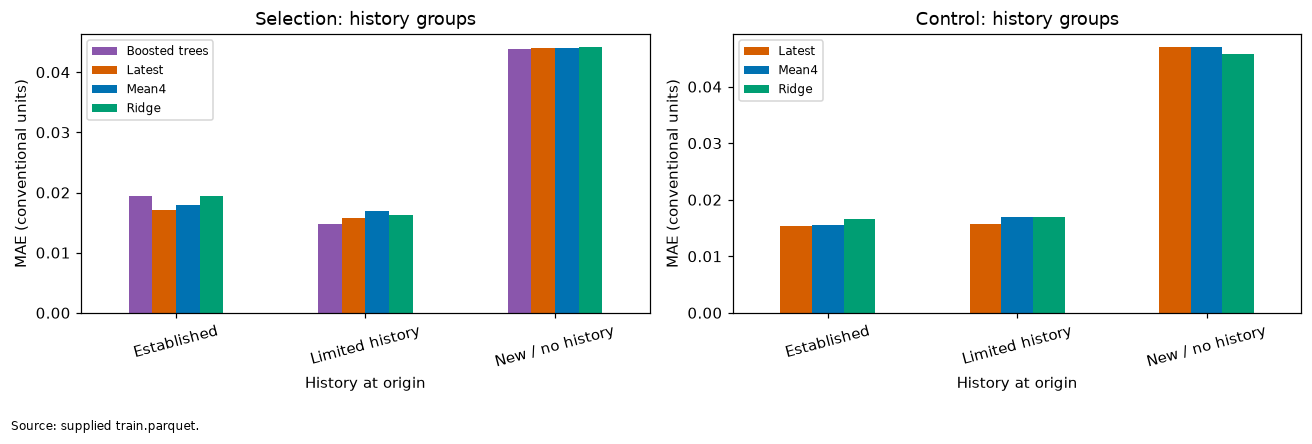

In [20]:
# Show where new-store and limited-history forecasts are weak
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for role, ax in zip(['Selection', 'Control'], axes):
    groups = group_metrics[group_metrics['role'] == role]
    table = groups.pivot(index='history_group', columns='method', values='MAE')
    table.plot.bar(ax=ax, color=[colors[m] for m in table.columns], rot=15)
    ax.set_title(role + ': history groups')
    ax.set_xlabel('History at origin')
    ax.set_ylabel('MAE (conventional units)')
    ax.legend(fontsize=8)
plt.figtext(0.01, 0.01, 'Source: supplied train.parquet.', fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIGURES / 'error_by_history_group.png', dpi=160)
plt.show()

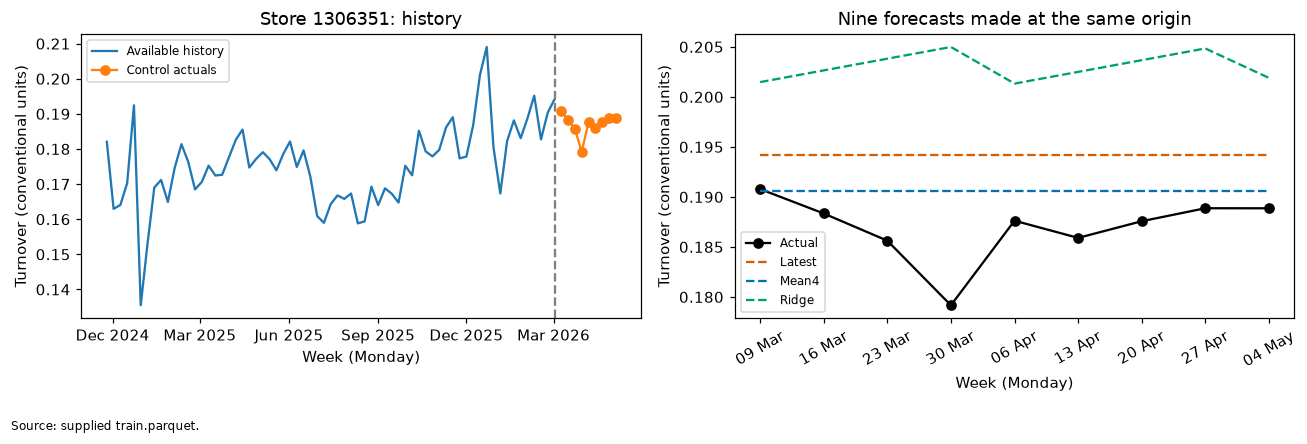

In [21]:
# Actual and predicted turnover for the example store
history = train[train['store_pseudo_id'] == example_id]
history = history[history['week'] <= control_date]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['week'], history['target'], label='Available history')
axes[0].plot(example_table.index, example_table['Actual'], 'o-', label='Control actuals')
axes[0].axvline(control_date, color='grey', linestyle='--')
axes[0].set_title('Store ' + str(example_id) + ': history')
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[1].plot(example_table.index, example_table['Actual'], 'o-', color='black', label='Actual')
for name in control_names:
    axes[1].plot(example_table.index, example_table[name], '--', color=colors[name], label=name)
axes[1].set_title('Nine forecasts made at the same origin')
axes[1].set_xticks(example_table.index)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
axes[1].tick_params(axis='x', rotation=30)
for ax in axes:
    ax.set_xlabel('Week (Monday)')
    ax.set_ylabel('Turnover (conventional units)')
    ax.legend(fontsize=8)
plt.figtext(0.01, 0.01, 'Source: supplied train.parquet.', fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIGURES / 'store_example.png', dpi=160)
plt.show()

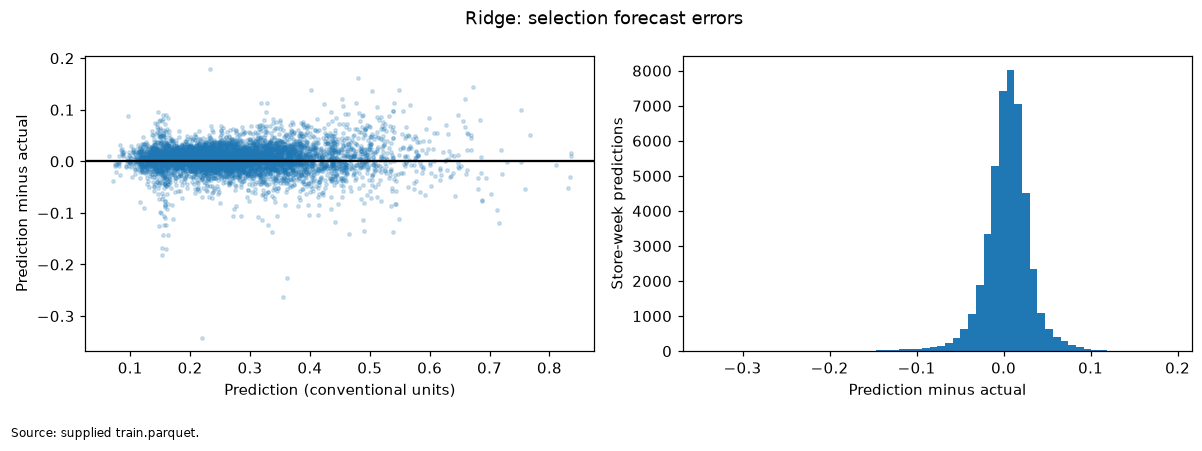

Figure source: supplied train.parquet; forecasts use only past turnover.


In [22]:
# Regression diagnostics: look for patterns in errors, not just a low average
errors = development[development['method'] == 'Ridge']
points = errors.sample(min(6000, len(errors)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(points['prediction'], points['error'], s=5, alpha=0.2)
axes[0].axhline(0, color='black')
axes[0].set_xlabel('Prediction (conventional units)')
axes[0].set_ylabel('Prediction minus actual')
axes[1].hist(errors['error'], bins=60)
axes[1].set_xlabel('Prediction minus actual')
axes[1].set_ylabel('Store-week predictions')
fig.suptitle('Ridge: selection forecast errors')
plt.figtext(0.01, 0.01, 'Source: supplied train.parquet.', fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIGURES / 'regression_diagnostics.png', dpi=160)
plt.show()
print('Figure source: supplied train.parquet; forecasts use only past turnover.')

## 12. Final forecast

Keep the choice fixed after control. Refit its statistics or regression through
4 May 2026 and predict only the supplied keys. The file includes stores without
history and preserves template order. Negative learned predictions are clipped
to zero in both evaluation and export; values above one are allowed.
Prediction CSVs are generated locally and excluded from Git. The saved notebook
shows summary checks rather than individual future predictions.

In [23]:
x_final = make_inputs(train, final_requests, final_date)
final_predictions = baseline_forecasts(train, x_final, final_date)
if selected_method in models:
    X, y, _ = training_examples(final_date)
    with threadpool_limits(limits=4):
        models[selected_method].fit(X, y)
        final_predictions[selected_method] = models[selected_method].predict(x_final[FEATURES])

final_forecast = test[KEY].copy()
final_forecast['target'] = final_predictions[selected_method].clip(lower=0).to_numpy()
final_forecast.to_csv(OUTPUT / 'final_forecast.csv', index=False, date_format='%Y-%m-%d')
saved = pd.read_csv(OUTPUT / 'final_forecast.csv', parse_dates=['week'])

# Show the checks so we can read the results before using the forecast
print('Forecast rows:', len(saved), '| Expected:', len(test))
print('Store-week pairs match the template:', saved[KEY].equals(test[KEY].reset_index(drop=True)))
print('Missing predictions:', saved['target'].isna().sum())
print('All predictions are finite:', np.isfinite(saved['target']).all())
print('Final method:', selected_method)
print('New-store rows:', saved['store_pseudo_id'].isin(new_ids).sum())

Forecast rows: 31586 | Expected: 31586
Store-week pairs match the template: True
Missing predictions: 0
All predictions are finite: True
Final method: Latest
New-store rows: 702


In [24]:
# Save concise results and a record of how each final prediction was produced
audit = x_final[KEY + ['history_group', 'has_history', 'n_recent', 'gap_weeks', 'last_date']].copy()
audit['method'] = selected_method
audit['forecast_route'] = final_predictions['route']
if selected_method in models:
    audit['forecast_route'] = 'direct_regression'
audit['target'] = final_forecast['target'].to_numpy()
audit.to_csv(OUTPUT / 'final_forecast_audit.csv', index=False, date_format='%Y-%m-%d')
all_results.to_csv(OUTPUT / 'validation_predictions.csv', index=False, date_format='%Y-%m-%d')
metrics(all_results, ['role', 'origin', 'method']).to_csv(OUTPUT / 'validation_metrics.csv', index=False)
group_metrics.to_csv(OUTPUT / 'group_metrics.csv', index=False)

control_metrics = metrics(control, ['method']).set_index('method')
summary = dict(frozen_selection)
summary['selection_scores'] = selection_scores.to_dict()
summary['control_MAE'] = float(control_metrics.loc[selected_method, 'MAE'])
summary['control_RMSE'] = float(control_metrics.loc[selected_method, 'RMSE'])
summary['control_Bias'] = float(control_metrics.loc[selected_method, 'Bias'])
summary['final_rows'] = len(saved)
summary['new_store_rows'] = int(saved['store_pseudo_id'].isin(new_ids).sum())
(OUTPUT / 'run_summary.json').write_text(json.dumps(summary, indent=2))

582

## 13. Interpretation for the presentation

The following text describes the supplied data and the fixed model settings above.
It is also available in `results/modeling_v2/report_sections.md`. If the data,
models or dates change, update the written interpretation after recomputing results.

# X5 modelling: methodology, models and results

## Methodology — data and methods

The supplied anonymised X5 data contain 321,531 store–week observations for
3,561 stores over 148 Mondays,
10 July 2023–4 May 2026. Turnover is in conventional units, not rubles or a percentage.
The prediction template requests 31,586 pairs for 11 May–6 July 2026,
including 168 stores with no training history (702 rows). We build on the team's
EDA_x5.ipynb, reusing date/calendar preparation and its data-quality findings.
Keys are unique, targets are finite and nonnegative, and zero is retained. Target
is neither logit-transformed nor capped at one; logarithms are applied only to
age and area predictors.

We compare complete forecasting procedures on all observed future keys after
3 March and 5 May 2025. Each origin predicts the next nine Mondays using only past
turnover. These periods select the method. A separate retrospective control after
2 March 2026 is run after freezing the choice. It was previously explored and is
not a blind test. Region, area and planned opening information are assumed known;
historical future store lists are treated as supplied requests, not predicted openings.

## Model(s) description

Latest repeats the last available turnover. Mean4 averages observations in the
latest four calendar weeks, uses a partial mean when necessary, and falls back to
the older last value if the recent window is empty. Both use the same past-only
peer median for no-history stores: region and age band, then age band nationally,
then all donors in the latest 52 weeks. Specific group levels require five stores.
Age bands and donor rules are starting heuristics rather than optimised thresholds.

One pooled direct Ridge regression predicts turnover from last turnover, recent
mean/count, history and gap indicators, horizon, log age/area, region and forecast
month. Training origins are spaced four weeks apart; each label is available by
the external cutoff, while each row's turnover inputs stop at its own origin.
Numeric scaling and category encoding are fitted on training only. Alpha is fixed
at one. A single nonlinear alternative, histogram gradient boosting, uses the same
information and grid with 150 iterations, 15 leaves, learning rate 0.06 and seed 42;
early stopping and hyperparameter search are disabled. Its hypothesis is that
nonlinear relationships and interactions suggested by EDA may improve forecasts.
Negative regression predictions are clipped to zero consistently. No upper cap applies.

MAE is the primary score, with equal weight for the two selection periods. RMSE
and mean prediction-minus-actual Bias supplement it. We inspect groups, horizons,
store-level errors and error plots; no OLS significance tests or prediction intervals
are claimed. Model choice uses the lowest selection score with exact ties favouring simplicity.

## Results and limitations

The frozen method is **Latest**. Its mean selection MAE is
**0.017624**, compared with
0.017624 for the best simple reference (Latest); the
relative improvement is 0.00%. The period winners are Mean4 after 03 Mar 2025; Latest after 05 May 2025.
Thus Latest does not win every period: smoothing helps in the first, while the
last observation works better in the May–July selection exercise. Ridge has mean
selection MAE 0.019471, and boosted trees
0.019158; neither improves on the
chosen simple reference under these fixed settings. This does not establish that
all regressions or boosted models would fail to improve it.
Control MAE is **0.016064**, RMSE 0.023941,
and Bias -0.004451. The fixed simple reference has control MAE
0.016064. For no-history control stores, MAE is 0.046959
over 588 requested rows and 131 stores.
The selected forecasts show average underprediction of 0.004451
conventional units. No-history MAE is 3.05
times the established-store MAE (0.015390), making new stores
a clear priority for further work. In the worked store, Mean4 wins all nine weeks;
that local result does not overturn the wider selection evidence.

The final forecast covers all 31,586 requested pairs in template order,
including every no-history row. These point forecasts can support planning comparisons,
but the data do not quantify monetary stockout/spoilage costs. Error variation across
stores and periods remains material. Only two periods select the method, the control
was previously seen, observed future rosters are assumed known, and profile availability
is an assumption. Neither error percentiles nor MAE are 95% prediction intervals.
The selected method is best among the tested candidates under this procedure;
it is not a proven optimum across models or a guarantee of future accuracy.

## Sources

- Supplied MSC_Briefing.pdf; MSC Project Assignment criteria.pdf; X5 Q&A workbook.
- Team EDA_x5.ipynb and original train.parquet/test_template.parquet.
- Hyndman and Athanasopoulos, Forecasting: Principles and Practice, chapters 5 and 7:
  https://otexts.com/fpp3/toolbox.html and https://otexts.com/fpp3/regression.html
- scikit-learn documentation: Ridge, HistGradientBoostingRegressor, preprocessing
  and cross-validation: https://scikit-learn.org/stable/

## Limits and next steps

The two selection periods do not guarantee future accuracy. The control was seen
in earlier work, profiles and future rosters are assumed known, and new-store
errors are materially higher. Variation between stores is not a calibrated
prediction interval. Relationships are predictive, not causal.

A further model or feature change needs a clear hypothesis and evaluation before
looking at its control errors. The final method is best among the tested settings,
not a proven optimum across all possible models.